#Task 1

Write a function that takes a grayscale image as argument and generates the histogram of that grayscale image. You can use any suitable grayscale image from here: https://www.imageprocessingplace.com/DIP-3E/dip3e_book_images_downloads.htm

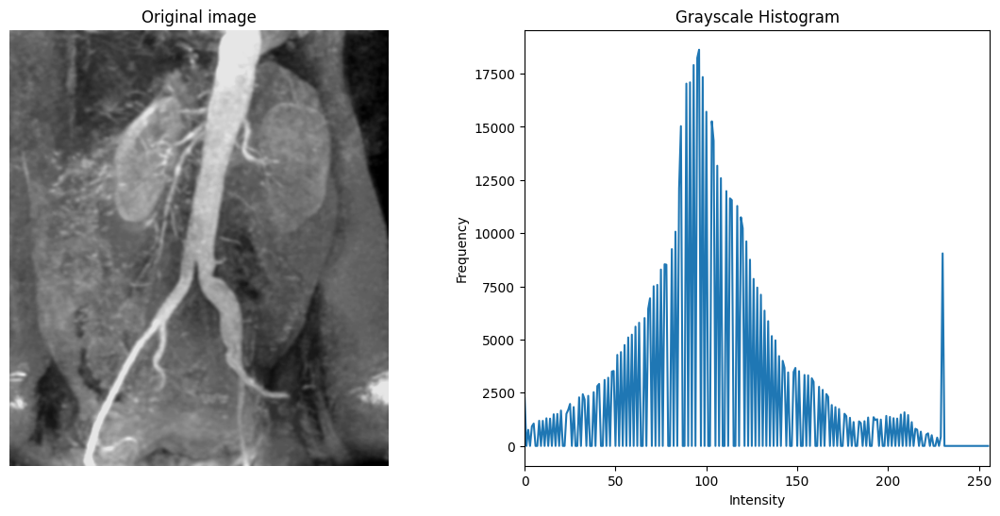

In [ ]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

def my_histogram(image):
    hist = cv2.calcHist([image], [0], None, [256], [0, 256])

    plt.figure(figsize=(14,6))

    plt.subplot(1, 2, 1)
    plt.imshow(image)
    plt.title("Original image")
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.plot(hist)
    plt.title("Grayscale Histogram")
    plt.xlabel("Intensity")
    plt.ylabel("Frequency")
    plt.xlim([0, 256])
    plt.show()

img = cv2.imread("/content/Fig0312(a)(kidney).tif")
my_histogram(img)

# Task 2
Take any suitable color image and divide it into 3 separate channels. Display the individual channels in their own color. For example, the red channel should generate a red image, where the intensity of red in each pixel will depend on how much red is present in that pixel in the original color image

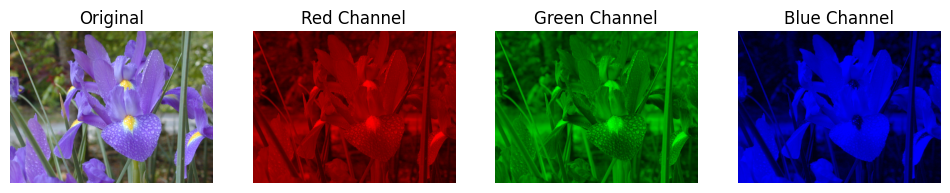

In [ ]:
import numpy as np

def show_color_channels(image_path):

    img = cv2.imread(image_path)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    R, G, B = cv2.split(img_rgb)

    zeros = np.zeros_like(R)

    red_image   = np.stack([R, zeros, zeros], axis=2)
    green_image = np.stack([zeros, G, zeros], axis=2)
    blue_image  = np.stack([zeros, zeros, B], axis=2)

    plt.figure(figsize=(12, 6))

    plt.subplot(1, 4, 1)
    plt.imshow(img_rgb)
    plt.title("Original")
    plt.axis("off")

    plt.subplot(1, 4, 2)
    plt.imshow(red_image)
    plt.title("Red Channel")
    plt.axis("off")

    plt.subplot(1, 4, 3)
    plt.imshow(green_image)
    plt.title("Green Channel")
    plt.axis("off")

    plt.subplot(1, 4, 4)
    plt.imshow(blue_image)
    plt.title("Blue Channel")
    plt.axis("off")

    plt.show()

    return R,G,B

red, green, blue =show_color_channels('/content/Fig0651(a)(flower_no_compression).tif')

# Task 3

Use your previously written histogram function from Task 1 to generate the histogram of color image. Since color images have 3 channels, so you will have 3 histograms. Analyze the histograms to determine which color is more dominant in the image.


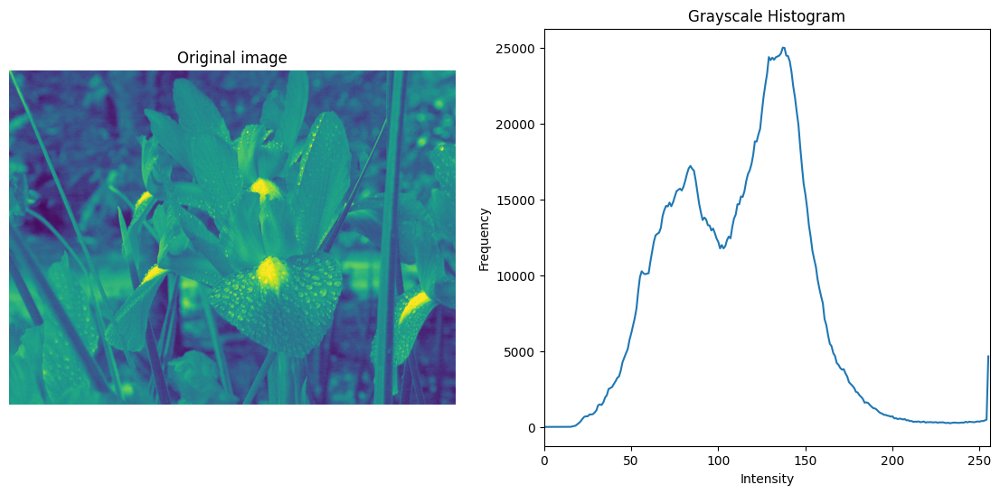

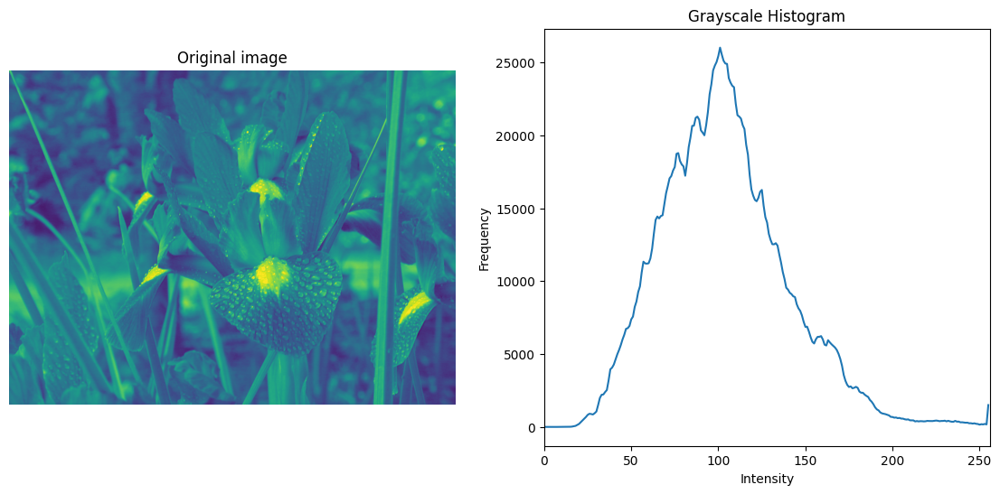

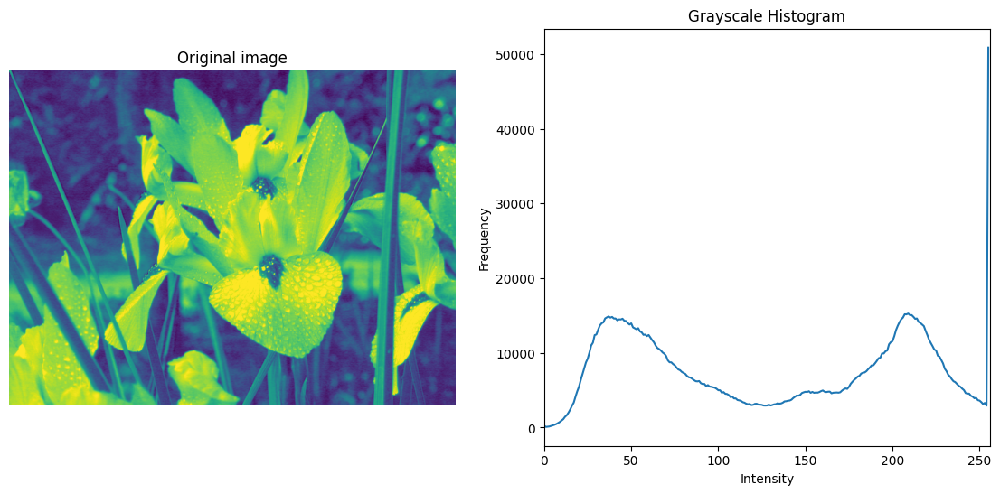

In [ ]:
my_histogram(red)
my_histogram(green)
my_histogram(blue)

# Task 4

Write a function that takes 3 parameters: a color image, a channel_number (0 for red, 1 for green and 2 for blue) and an enhancement value between 0 and 1, and returns an enhanced version of the image. Show the enhanced image. As an example, refer to the following image which shows the result for red enhancement.
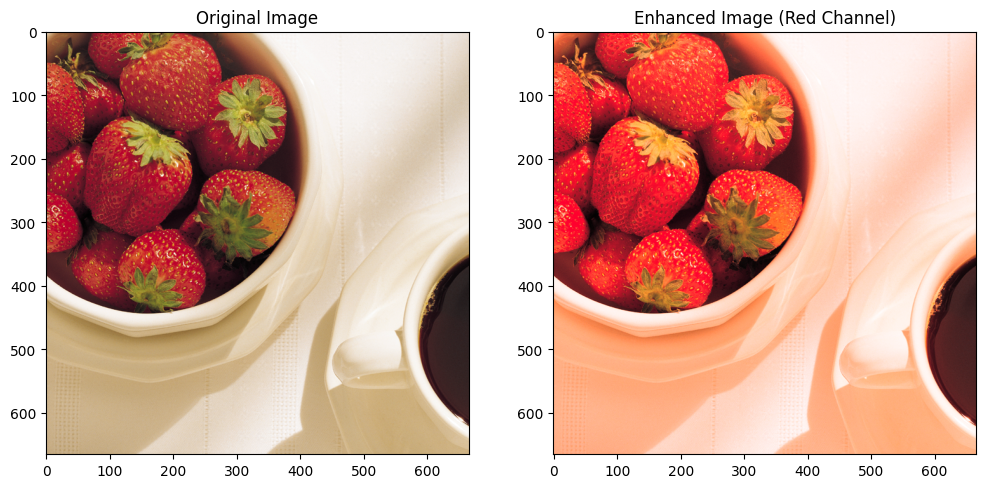

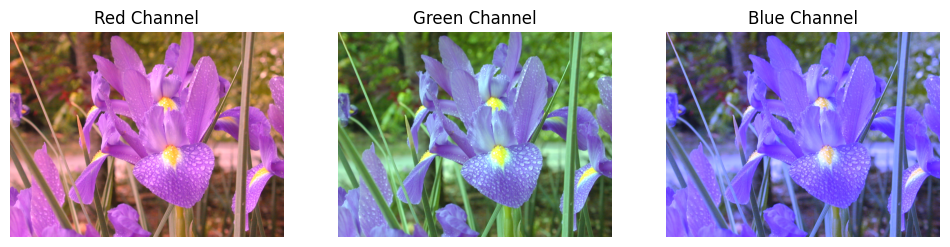

In [ ]:
def color_enhance(color_image, channel_number, enhancement_val):

    img_rgb = cv2.cvtColor(color_image, cv2.COLOR_BGR2RGB)
    enhanced = img_rgb.astype(np.float32)

    enhanced[:, :, channel_number] *= (1 + enhancement_val)
    enhanced = np.clip(enhanced, 0, 255).astype(np.uint8)

    return enhanced

img = cv2.imread("/content/Fig0651(a)(flower_no_compression).tif")

enhanced_red = color_enhance(img, 0, 0.5)
enhanced_green = color_enhance(img, 1, 0.3)
enhanced_blue = color_enhance(img, 2, 1.0)

plt.figure(figsize=(12, 6))

plt.subplot(1, 3, 1)
plt.imshow(enhanced_red)
plt.title("Red Channel")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(enhanced_green)
plt.title("Green Channel")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(enhanced_blue)
plt.title("Blue Channel")
plt.axis("off")

plt.show()

#Task 5

Write a function that takes a grayscale image as argument and returns the negative of that image. For an 8-bit image, it follows:

$$g(x,y) = L_{max} - f(x,y);$$
where $L_{max}=255$

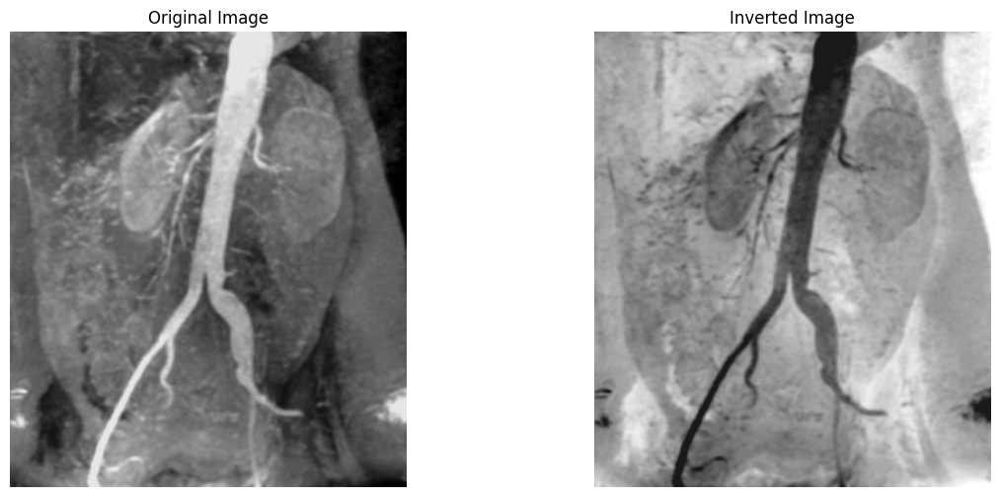

In [ ]:
def invert_gray(gray_image):
  Lmax = 255
  inverted_image = Lmax - gray_image
  return inverted_image

gray_image = cv2.imread("/content/Fig0312(a)(kidney).tif")

inverted_image = invert_gray(gray_image)

plt.figure(figsize=(14, 6))

plt.subplot(1,2,1)
plt.imshow(gray_image, cmap='gray')
plt.title("Original Image")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(inverted_image, cmap='gray')
plt.title("Inverted Image")
plt.axis("off")

plt.show()


#Task 6

Extend your function so that it works for color images too.

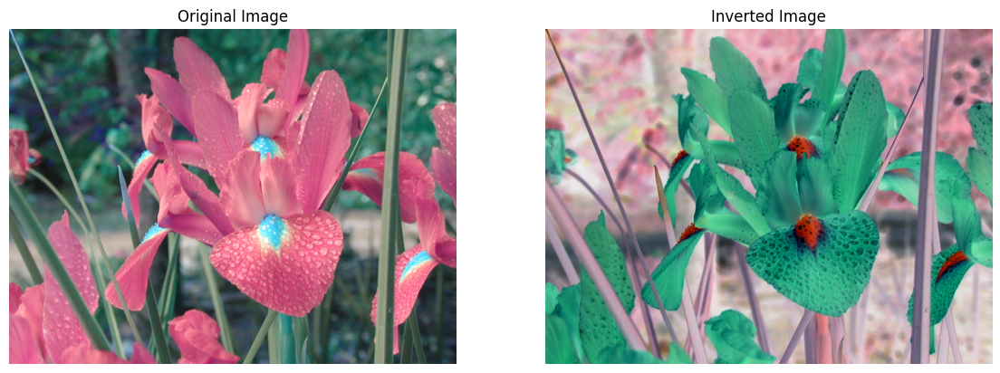

In [ ]:
def invert_color(color_image):
  return invert_gray(color_image)

color_image = cv2.imread("/content/Fig0651(a)(flower_no_compression).tif")

inverted_image = invert_color(color_image)

plt.figure(figsize=(14, 6))

plt.subplot(1,2,1)
plt.imshow(color_image, cmap='gray')
plt.title("Original Image")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(inverted_image, cmap='gray')
plt.title("Inverted Image")
plt.axis("off")

plt.show()

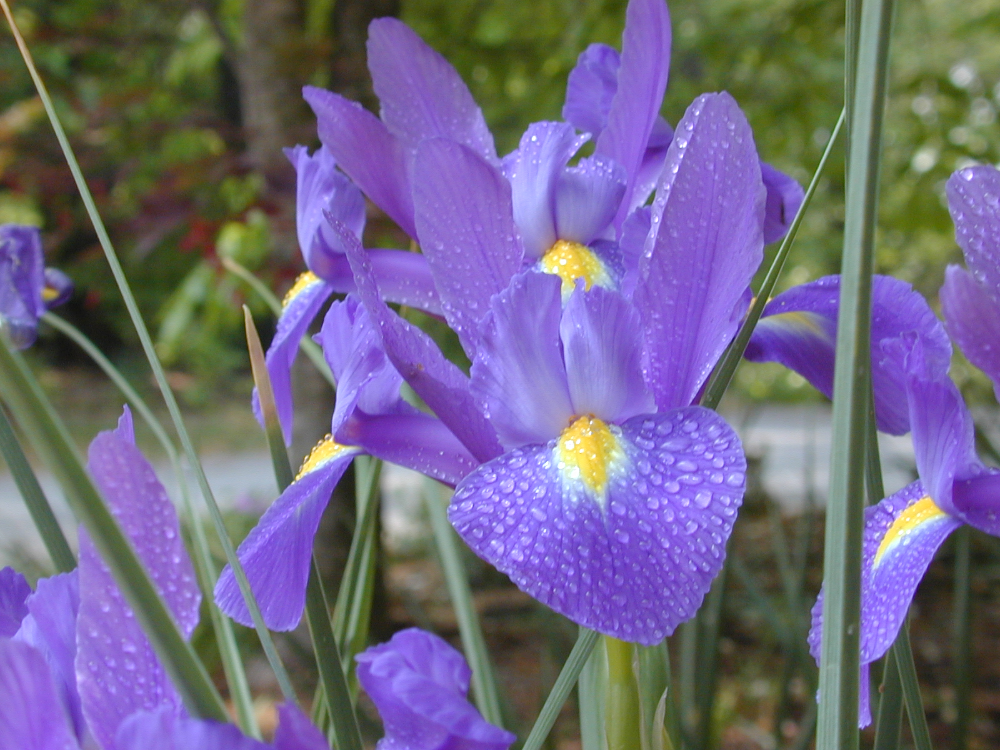

In [ ]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

img = Image.open('/content/Fig0651(a)(flower_no_compression).tif')
M = np.asarray(img)

#print(M)
img
#plt.imshow(img, cmap='gray')
#plt.imshow(M, cmap='gray')

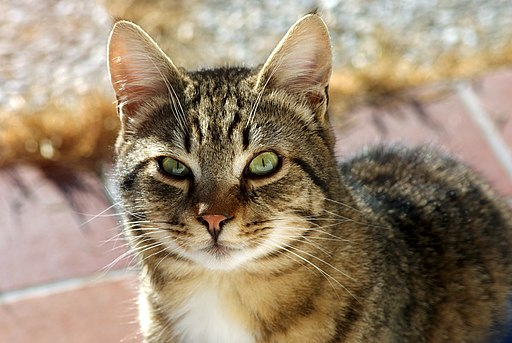

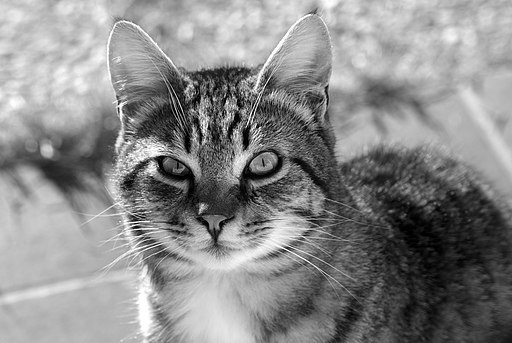

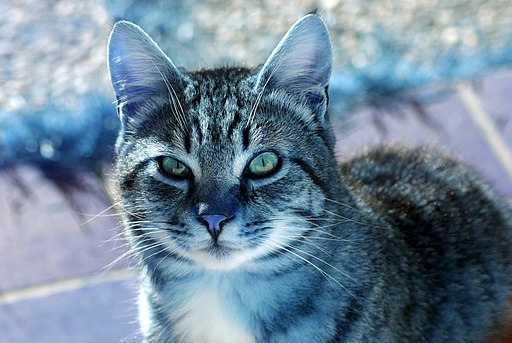

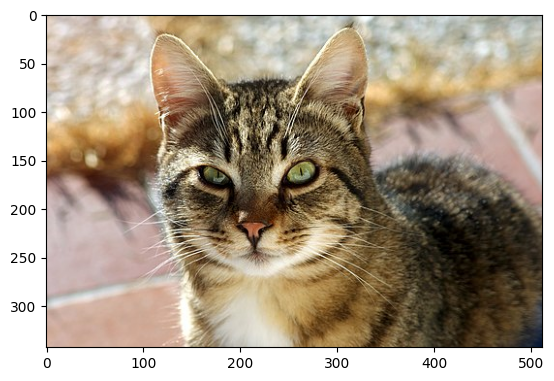

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab.patches import cv2_imshow

img = cv2.imread("/content/cat.jpg")
cv2_imshow(img)

grayimg = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
cv2_imshow(grayimg)

# Serves the same purpose
# img = cv2.imread("/content/cat.jpg", cv2.IMREAD_GRAYSCALE)
# cv2_imshow(img)

# Converts from BGR to RGB
img2 = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
cv2_imshow(img2)

# pyplot displays in RGB format
plt.imshow(img2)